# EDA – hommelgeluiden (gecombineerde versie)

**Datalab 3 · verkennende data-analyse**

Dit notebook voegt onze twee eerdere EDA's samen: `eda.ipynb` en `eda 2.ipynb` (met de toelichting in `eda_uitleg.ipynb`). Uitleg en code staan nu in één bestand.

We volgen de 6 EDA-stappen uit de les:

1. **Context** – wat betekent de data?
2. **Structuur** – rijen, kolommen, typen
3. **Kwaliteit** – missing, fouten, duplicaten
4. **1 variabele** – verdeling / categorieën
5. **Relaties** – wat beweegt samen?
6. **Vervolgvragen** – wat willen we uitzoeken?

*Eerst kijken → dan vragen stellen → pas daarna verklaren of modelleren.* Bij elke stap staat eerst de **observatie**; een mogelijke verklaring noemen we een **hypothese**.

**Belangrijk verschil met de eerdere versies:** de dataset bevat opnames van twee soorten recorders (16 kHz en 384 kHz). Daardoor kunnen verschillen tussen klassen eigenlijk verschillen tussen recorders zijn. Waar dat uitmaakt, kijken we daarom ook naar alleen de 16 kHz-opnames (stap 5).

## 1. Context – wat betekent de data?

- **Opdrachtgever:** Lectoraat Smart Sensor Systems, De Haagse Hogeschool (Sam Aerts). De opnames en labels komen uit een eerdere stage (Jasper Schoen).
- **Klantvraag:** automatisch herkennen wat een **hommel** doet op basis van geluid, vooral *buzz pollination* (`buzz`) en vliegen (`flight`). Het gaat om opnames bij bloemen, niet om een bijenkast.
- **Ruwe data:** 150 WAV-opnames in `raw_data/`. De bestandsnaam is het starttijdstip (`YYYYMMDD_HHMMSS.WAV`).
- **Labels:** `raw_labels/buzzdetection_labels.csv` – handmatig, één rij per seconde.
- **Dataset voor deze EDA:** `processed_data/bee_features_per_second.csv`, gemaakt door `preprocessdata.py`.

**Eén rij = één seconde geluid.** Per seconde zijn er 64 numerieke features:

| Kolommen | Betekenis |
|---|---|
| `start`, `end` | tijdstip van deze seconde |
| `label` | gedragsklasse (doelvariabele) – leeg als de seconde niet gelabeld is |
| `source_file` | WAV-bestand waar de seconde uit komt |
| `mfcc_1..20_mean` / `_std` | MFCC's: de klankkleur (het spectrale profiel) van het geluid, gemiddelde en spreiding binnen de seconde |
| `delta_1..20_mean` | hoe snel de MFCC's veranderen binnen de seconde |
| `zcr_mean` | zero-crossing rate – hoe ruisachtig of hoogfrequent het signaal is |
| `rms_mean` | gemiddelde energie (luidheid) |
| `spectral_centroid_mean` | "helderheid": het zwaartepunt van het spectrum (Hz) |
| `spectral_rolloff_mean` | frequentie waaronder 85% van de energie ligt (Hz) |

De belangrijkste variabele is **`label`**: dat is wat het model later moet voorspellen.

In [46]:
import glob
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler

DATA_CSV = "processed_data/bee_features_per_second.csv"
LABELS_CSV = "raw_labels/buzzdetection_labels.csv"
RAW_DATA_DIR = "raw_data"

# Vaste volgorde en vaste kleur per klasse: een klasse heeft in elke grafiek dezelfde kleur.
KLASSEN = ["buzz", "flight", "noise", "radio", "voice"]
KLEUR = {
    "buzz": "#2a78d6",
    "flight": "#eb6834",
    "noise": "#1baf7a",
    "radio": "#eda100",
    "voice": "#e87ba4",
}
GRIJS = "#898781"      # geen label / context
LICHTGRIJS = "#d6d5cf" # achtergrondpunten
ACCENT = "#4a3aa7"     # uitgelichte groep die geen klasse is (384 kHz-opnames)
INKT = "#0b0b0b"
INKT_2 = "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.size": 10,
    "text.color": INKT,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": INKT_2,
    "axes.edgecolor": "#c3c2b7",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "xtick.color": GRIJS,
    "ytick.color": GRIJS,
    "xtick.labelcolor": INKT_2,
    "ytick.labelcolor": INKT_2,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)

BOX_STIJL = dict(
    patch_artist=True, widths=0.55,
    medianprops=dict(color=INKT, linewidth=1.4),
    whiskerprops=dict(color=GRIJS, linewidth=0.9),
    capprops=dict(color=GRIJS, linewidth=0.9),
    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=GRIJS, markeredgecolor="none", alpha=0.5),
)


def boxplot_per_klasse(ax, data, kolom, toon_uitschieters=True):
    """Boxplot van één feature per klasse, in de vaste volgorde en kleuren."""
    bp = ax.boxplot([data.loc[data["label"] == k, kolom] for k in KLASSEN], tick_labels=KLASSEN,
                    showfliers=toon_uitschieters, **BOX_STIJL)
    for vak, klasse in zip(bp["boxes"], KLASSEN):
        vak.set(facecolor=KLEUR[klasse], edgecolor="none")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)

## 2. Structuur – rijen, kolommen, typen

De eerste 5 checks uit de les: `shape`, `head()`, `info()`, `isna().sum()` en `describe()`.

In [47]:
# skipinitialspace + strip: het CSV-bestand is soms met uitgelijnde kolommen (extra spaties) opgeslagen.
df_raw = pd.read_csv(DATA_CSV, skipinitialspace=True)
df_raw.columns = df_raw.columns.str.strip()
TEKST_KOLOMMEN = ["start", "end", "label", "source_file"]
for kolom in TEKST_KOLOMMEN:
    df_raw[kolom] = df_raw[kolom].str.strip()

FEATURES = [k for k in df_raw.columns if k not in TEKST_KOLOMMEN]

print("Rijen, kolommen:", df_raw.shape)
print("Aantal features:", len(FEATURES))

Rijen, kolommen: (18396, 68)
Aantal features: 64


In [48]:
df_raw.head()

,start,end,label,source_file,mfcc_1_mean,mfcc_1_std,...,mfcc_20_std,delta_20_mean,zcr_mean,rms_mean,spectral_centroid_mean,spectral_rolloff_mean
0,2026-03-24 11:13:01,2026-03-24 11:13:02,buzz,20260324_111301.WAV,-213.332703,9.969483,...,3.792938,-0.011226,0.083264,0.045808,1674.210640,4107.638889
1,2026-03-24 11:13:02,2026-03-24 11:13:03,buzz,20260324_111301.WAV,-216.638199,16.160877,...,3.735661,-0.017726,0.072971,0.045750,1511.058403,3478.670635
2,2026-03-24 11:13:03,2026-03-24 11:13:04,buzz,20260324_111301.WAV,-203.581894,27.382261,...,4.425210,0.073318,0.112026,0.054339,1884.075143,4271.825397
3,2026-03-24 11:13:04,2026-03-24 11:13:05,buzz,20260324_111301.WAV,-194.708817,19.923811,...,4.670153,-0.001011,0.127217,0.051827,2131.932958,4570.436508
4,2026-03-24 11:13:05,2026-03-24 11:13:06,flight,20260324_111301.WAV,-189.831085,15.907944,...,5.040837,0.060674,0.159714,0.045216,2377.590768,4941.964286


In [49]:
df_raw.info(verbose=False)
print()
print(df_raw.dtypes.astype(str).value_counts().rename("aantal kolommen"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18396 entries, 0 to 18395
Columns: 68 entries, start to spectral_rolloff_mean
dtypes: float64(64), object(4)
memory usage: 9.5+ MB

float64    64
object      4
Name: aantal kolommen, dtype: int64


In [50]:
missing = df_raw.isna().sum()
print("Kolommen met ontbrekende waarden:")
print(missing[missing > 0])
print(f"\nAandeel rijen zonder label: {df_raw['label'].isna().mean():.1%}")

Kolommen met ontbrekende waarden:
label    10964
dtype: int64

Aandeel rijen zonder label: 59.6%


In [51]:
df_raw[TEKST_KOLOMMEN].describe()

,start,end,label,source_file
count,18396,18396,7432,18396
unique,9198,9198,5,150
top,2026-05-26 12:15:57,2026-05-26 12:15:58,radio,20260408_092023.WAV
freq,2,2,3312,1066


In [52]:
BASIS = ["rms_mean", "zcr_mean", "spectral_centroid_mean", "spectral_rolloff_mean"]
df_raw[BASIS + ["mfcc_1_mean", "mfcc_2_mean"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
rms_mean,18396.0,0.069,0.054,0.020,0.047,0.052,0.064,0.767
zcr_mean,18396.0,0.067,0.028,0.009,0.052,0.059,0.072,0.354
spectral_centroid_mean,18396.0,1095.974,316.997,387.925,910.314,995.187,1138.915,3172.483
spectral_rolloff_mean,18396.0,2241.933,808.838,576.885,1749.008,2005.208,2392.857,6242.063
mfcc_1_mean,18396.0,-218.182,31.649,-312.265,-239.686,-227.216,-206.238,-10.347
mfcc_2_mean,18396.0,98.291,15.660,18.200,93.504,102.027,108.432,134.061


**Noteer meteen:**

| | |
|---|---|
| Rijen | **18.396** |
| Kolommen | **68** (4 tekst + 64 numerieke features) |
| Kolommen met missings | **1** – alleen `label` (59,6% leeg); de features zijn compleet |
| Verdachte datatypes | **2** – `start` en `end` zijn tekst, geen datetime |

**Wat opvalt:**

- `start` komt 18.396 keer voor maar heeft maar 9.198 unieke waarden, en de meest voorkomende waarde komt precies 2 keer voor. Dat is verdacht → stap 3.
- **De schalen van de features verschillen enorm:** `mfcc_1_mean` ligt rond −220, `rms_mean` rond 0,05 en `spectral_rolloff_mean` in de duizenden Hz. Voor modellen die gevoelig zijn voor schaal (kNN, SVM, logistische regressie, PCA) moeten we de features dus standaardiseren.

## 3. Kwaliteit – missing, fouten, duplicaten

> *Niet "fixen" voordat je begrijpt waarom iets vreemd is.*

### 3.1 Duplicaten

In [53]:
n_dubbel = df_raw.duplicated().sum()
print(f"Volledig identieke rijen:   {n_dubbel} van {len(df_raw)} ({n_dubbel / len(df_raw):.0%})")
print(f"Dubbel op (start, bestand): {df_raw.duplicated(subset=['start', 'source_file']).sum()}")
print(f"Dubbele feature-vectoren:   {df_raw[FEATURES].duplicated().sum()}")

per_seconde = df_raw.groupby(["source_file", "start"]).size()
print("\nHoe vaak komt elke seconde voor?")
print(per_seconde.value_counts().rename("aantal seconden"))

Volledig identieke rijen:   9198 van 18396 (50%)
Dubbel op (start, bestand): 9198
Dubbele feature-vectoren:   9198

Hoe vaak komt elke seconde voor?
2    9198
Name: aantal seconden, dtype: int64


**Observatie:** elke seconde staat **precies 2 keer** in de dataset (9.198 dubbele rijen = 50%), met identieke tijd, bestand en features.

**Oorzaak (nagekeken in de code):** `preprocessdata.py` zoekt eerst naar `*.WAV` en daarna naar `*.wav` en telt beide lijsten op. Op een bestandssysteem dat geen verschil maakt tussen hoofd- en kleine letters (Windows, macOS) vindt het script daardoor elk bestand twee keer.

**Besluit voor deze EDA:** we werken verder met de ontdubbelde dataset `df` (9.198 unieke seconden). Het script passen we later aan, zodat het bestand opnieuw gegenereerd kan worden.

In [54]:
df = df_raw.drop_duplicates().reset_index(drop=True)
df["start_dt"] = pd.to_datetime(df["start"])
df["datum"] = df["start_dt"].dt.date
print("Na ontdubbelen:", df.shape)
print(f"Gelabeld: {df['label'].notna().sum()}  |  zonder label: {df['label'].isna().sum()} ({df['label'].isna().mean():.1%})")

Na ontdubbelen: (9198, 70)
Gelabeld: 3716  |  zonder label: 5482 (59.6%)


### 3.2 Ontbrekende labels – waar zitten ze?

In [55]:
per_bestand = df.groupby("source_file").agg(
    seconden=("label", "size"),
    gelabeld=("label", "count"),
    aantal_labels=("label", "nunique"),
)

geen = (per_bestand["gelabeld"] == 0).sum()
volledig = (per_bestand["gelabeld"] == per_bestand["seconden"]).sum()
deels = len(per_bestand) - geen - volledig
print(f"Bestanden totaal:        {len(per_bestand)}")
print(f"  volledig gelabeld:     {volledig}")
print(f"  gedeeltelijk gelabeld: {deels}")
print(f"  helemaal geen label:   {geen}")

print("\nAantal verschillende labels per gelabeld bestand:")
print(per_bestand.loc[per_bestand["gelabeld"] > 0, "aantal_labels"].value_counts().sort_index().rename("bestanden"))

print("\nSeconden per opnamedag:")
print(pd.crosstab(df["datum"], df["label"].fillna("(geen label)"), margins=True, margins_name="totaal"))

Bestanden totaal:        150
  volledig gelabeld:     55
  gedeeltelijk gelabeld: 28
  helemaal geen label:   67

Aantal verschillende labels per gelabeld bestand:
aantal_labels
1    37
2    26
3    20
Name: bestanden, dtype: int64

Seconden per opnamedag:
label       (geen label)  buzz  flight  noise  radio  voice  totaal
datum                                                              
2026-03-24             0    13       7      5    189      4     218
2026-04-08           533     0       0      0      0      0     533
2026-04-13             0    37       5      7    251      0     300
2026-04-24            55     0       0      0      0      0      55
2026-05-26          4894    89      99    289   1216   1505    8092
totaal              5482   139     111    301   1656   1509    9198


### 3.3 Lengte van de opnames

In [56]:
print(per_bestand["seconden"].describe().round(1))
print("\nOpnames korter dan 30 seconden:")
print(per_bestand.loc[per_bestand["seconden"] < 30, "seconden"].sort_values())
print("\nLangste opname:", per_bestand["seconden"].idxmax(), "-", per_bestand["seconden"].max(), "seconden")

count    150.0
mean      61.3
std       39.6
min        1.0
25%       60.0
50%       60.0
75%       60.0
max      533.0
Name: seconden, dtype: float64

Opnames korter dan 30 seconden:
source_file
20260526_121400.WAV     1
20260526_112051.WAV     9
20260526_103800.WAV    19
20260413_113700.WAV    26
20260526_121532.WAV    26
Name: seconden, dtype: int64

Langste opname: 20260408_092023.WAV - 533 seconden


**Observatie:** de meeste opnames duren 60 seconden. Eén opname duurt 533 seconden (8 april, zonder labels) en vijf zijn korter dan 30 seconden, waarvan één maar 1 seconde.

### 3.4 Sluiten de labels aan op de audio?

In [57]:
labels = pd.read_csv(LABELS_CSV)
labels["seconde"] = labels["start"].str[:19]   # '2026-03-24 11:13:01:00' -> zonder het laatste ':00'

print("Rijen in labelbestand:", len(labels))
print("Dubbele seconden in labelbestand:", labels["seconde"].duplicated().sum())

zonder_audio = labels[~labels["seconde"].isin(df["start"])]
print(f"Labels zonder bijbehorende audio-seconde: {len(zonder_audio)}")
print(zonder_audio["seconde"].str[:16].value_counts().sort_index().rename("labels per minuut"))

print("\nKolom 'opmerking':")
print(labels["opmerking"].value_counts(dropna=False))
print("\nLabels bij 'background voices':", list(labels.loc[labels["opmerking"] == "background voices", "label"].unique()))
print("Klassen in de data:", sorted(df["label"].dropna().unique()))

Rijen in labelbestand: 3797
Dubbele seconden in labelbestand: 0
Labels zonder bijbehorende audio-seconde: 81
seconde
2026-03-24 12:04     4
2026-04-13 11:31    55
2026-04-13 11:32     5
2026-04-13 11:33     6
2026-04-13 11:35     5
2026-04-13 11:36     5
2026-04-13 11:37     1
Name: labels per minuut, dtype: int64

Kolom 'opmerking':
opmerking
NaN                  3058
(derek)               697
background voices      42
Name: count, dtype: int64

Labels bij 'background voices': ['radio']
Klassen in de data: ['buzz', 'flight', 'noise', 'radio', 'voice']


**Observaties:**

- **81 labels hebben geen audio.** 55 daarvan horen bij minuut `2026-04-13 11:31` en 4 bij `2026-03-24 12:04` – voor die minuten is er geen WAV-bestand. De overige 22 liggen ná het einde van opnames op 13 april die maar ± 55 seconden duren, terwijl er 60 seconden gelabeld zijn.
- De kolom `opmerking` heeft twee waarden: `(derek)` (697 rijen) en `background voices` (42 rijen, allemaal gelabeld als `radio`).
- De klasse **`silence`** uit de README komt **niet voor** in de labels.

### 3.5 Twee soorten opnames

In [58]:
samplerate = {os.path.basename(p): sf.info(p).samplerate for p in glob.glob(os.path.join(RAW_DATA_DIR, "**", "*.WAV"), recursive=True)}
df["samplerate"] = df["source_file"].map(samplerate)
df["recorder"] = df["samplerate"].map({16000: "16 kHz", 384000: "384 kHz"})

print("Bestanden per samplerate:")
print(pd.Series(samplerate).value_counts().rename("aantal bestanden"))
print("\nSeconden per label en recorder:")
print(pd.crosstab(df["label"].fillna("(geen label)"), df["recorder"]))
print("\nOpnamedagen per recorder:")
print(df.groupby("recorder")["datum"].unique())

Bestanden per samplerate:
16000     138
384000     12
Name: aantal bestanden, dtype: int64

Seconden per label en recorder:
recorder      16 kHz  384 kHz
label                        
(geen label)    4894      588
buzz              89       50
flight            99       12
noise            289       12
radio           1216      440
voice           1505        4

Opnamedagen per recorder:
recorder
16 kHz                                         [2026-05-26]
384 kHz    [2026-03-24, 2026-04-08, 2026-04-13, 2026-04-24]
Name: datum, dtype: object


**Observatie:** 12 bestanden (maart/april) zijn opgenomen op **384 kHz**, de andere 138 (26 mei) op **16 kHz**. Het script brengt alles terug naar 16 kHz, maar het blijven twee verschillende soorten opnames. 50 van de 139 `buzz`-seconden (36%) komen uit de 384 kHz-opnames.

## 4. Eén variabele – verdeling / categorieën

### 4.1 Categorisch: hoe vaak komt elk label voor?

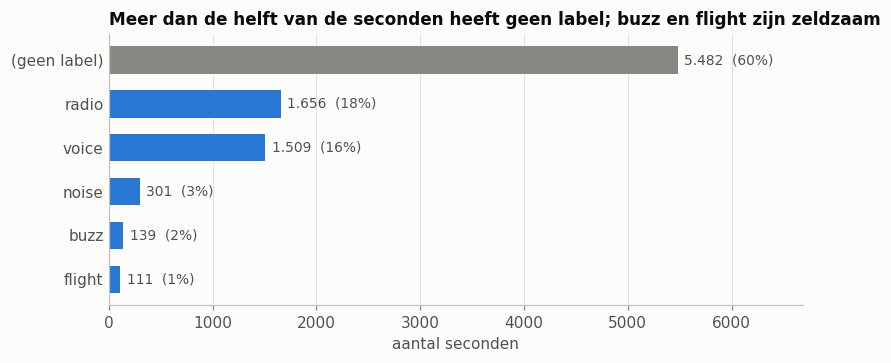

Verdeling binnen de gelabelde seconden:
        seconden  aandeel  bestanden
label                               
buzz         139    0.037         13
flight       111    0.030         26
noise        301    0.081         32
radio       1656    0.446         41
voice       1509    0.406         37

Onbalans (grootste / kleinste klasse): 14.9


In [59]:
telling = df["label"].fillna("(geen label)").value_counts().sort_values()
aandeel = telling / telling.sum()

fig, ax = plt.subplots(figsize=(7.5, 3.4))
kleuren = [GRIJS if naam == "(geen label)" else KLEUR["buzz"] for naam in telling.index]
ax.barh(telling.index, telling.values, color=kleuren, height=0.62)
for y, (n, a) in enumerate(zip(telling.values, aandeel.values)):
    ax.text(n + 60, y, f"{n:,}".replace(",", ".") + f"  ({a:.0%})", va="center", color=INKT_2, fontsize=9)
ax.set_xlim(0, telling.max() * 1.22)
ax.set_xlabel("aantal seconden")
ax.set_title("Meer dan de helft van de seconden heeft geen label; buzz en flight zijn zeldzaam")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

lab = df.dropna(subset=["label"]).copy()
gelabeld = lab["label"].value_counts()
print("Verdeling binnen de gelabelde seconden:")
print(pd.DataFrame({
    "seconden": gelabeld,
    "aandeel": (gelabeld / gelabeld.sum()).round(3),
    "bestanden": lab.groupby("label")["source_file"].nunique(),
}))
print(f"\nOnbalans (grootste / kleinste klasse): {gelabeld.max() / gelabeld.min():.1f}")

**Observatie:** de klassen zijn **sterk onevenwichtig**: de grootste klasse (`radio`) is bijna 15 keer zo groot als de kleinste (`flight`). Juist de klassen die over de hommels gaan zijn het zeldzaamst, en `buzz` komt maar in 13 bestanden voor.

Vanaf hier gebruiken we voor vergelijkingen tussen klassen alleen de **3.716 gelabelde seconden** (`lab`).

### 4.2 Numeriek: hoe zijn de basisfeatures verdeeld?

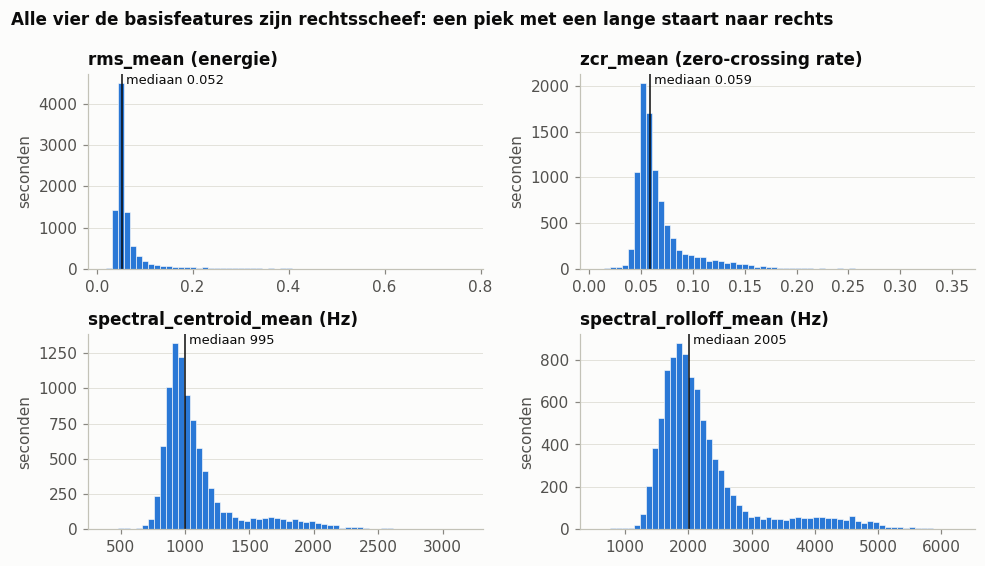

Scheefheid (0 = symmetrisch):
rms_mean                  4.70
zcr_mean                  2.64
spectral_centroid_mean    2.12
spectral_rolloff_mean     1.90
dtype: float64


In [60]:
titels = {
    "rms_mean": "rms_mean (energie)",
    "zcr_mean": "zcr_mean (zero-crossing rate)",
    "spectral_centroid_mean": "spectral_centroid_mean (Hz)",
    "spectral_rolloff_mean": "spectral_rolloff_mean (Hz)",
}
fig, axes = plt.subplots(2, 2, figsize=(9, 5.2))
for ax, kolom in zip(axes.ravel(), BASIS):
    ax.hist(df[kolom], bins=60, color=KLEUR["buzz"], edgecolor="#fcfcfb", linewidth=0.4)
    mediaan = df[kolom].median()
    ax.axvline(mediaan, color=INKT, linewidth=1)
    tekst = f"{mediaan:.0f}" if mediaan >= 10 else f"{mediaan:.3f}"
    ax.text(mediaan, ax.get_ylim()[1], f" mediaan {tekst}", va="top", ha="left", fontsize=8.5, color=INKT)
    ax.set_title(titels[kolom])
    ax.set_ylabel("seconden")
    ax.grid(axis="x", visible=False)
fig.suptitle("Alle vier de basisfeatures zijn rechtsscheef: een piek met een lange staart naar rechts",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

print("Scheefheid (0 = symmetrisch):")
print(df[BASIS].skew().round(2))

### 4.3 Uitschieters

Twee manieren: de IQR-regel voor één feature (`rms_mean`) en een z-score over alle 64 features.

In [61]:
q1, q3 = df["rms_mean"].quantile([0.25, 0.75])
grens = q3 + 1.5 * (q3 - q1)
uit_rms = df["rms_mean"] > grens
print(f"rms_mean boven Q3 + 1,5 × IQR ({grens:.3f}): {uit_rms.sum()} seconden ({uit_rms.mean():.1%})")
print("\nDe 5 hardste seconden:")
print(df.nlargest(5, "rms_mean")[["start", "source_file", "label", "rms_mean"]].to_string(index=False))

z = ((df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()).abs()
uit_z = (z > 4).any(axis=1)
print(f"\nRijen met minstens één feature met |z| > 4: {uit_z.sum()} ({uit_z.mean():.1%})")
print("\nFeatures met de meeste uitschieters:")
print((z > 4).sum().sort_values(ascending=False).head(6).rename("rijen"))

print("\nAandeel rijen met |z| > 4, per label en per recorder:")
print(uit_z.groupby(df["label"].fillna("(geen label)")).mean().round(3).rename("aandeel"))
print(uit_z.groupby(df["recorder"]).mean().round(3).rename("aandeel"))

rms_mean boven Q3 + 1,5 × IQR (0.091): 1108 seconden (12.0%)

De 5 hardste seconden:
              start         source_file label  rms_mean
2026-05-26 10:27:49 20260526_102700.WAV   NaN  0.767114
2026-05-26 11:20:54 20260526_112051.WAV   NaN  0.721804
2026-05-26 11:20:59 20260526_112051.WAV   NaN  0.698645
2026-05-26 11:20:55 20260526_112051.WAV   NaN  0.656152
2026-05-26 11:20:53 20260526_112051.WAV   NaN  0.628006

Rijen met minstens één feature met |z| > 4: 1031 (11.2%)

Features met de meeste uitschieters:
rms_mean        151
delta_1_mean    106
mfcc_8_std       99
mfcc_1_std       96
mfcc_5_std       84
zcr_mean         72
Name: rijen, dtype: int64

Aandeel rijen met |z| > 4, per label en per recorder:
label
(geen label)    0.132
buzz            0.086
flight          0.009
noise           0.173
radio           0.068
voice           0.084
Name: aandeel, dtype: float64
recorder
16 kHz     0.086
384 kHz    0.302
Name: aandeel, dtype: float64


**Observatie:** ongeveer 11–12% van de seconden is een uitschieter, vooral in `rms_mean` (harde geluiden) en de delta's (plotselinge veranderingen). Uitschieters komen bij **alle labels** voor: het vaakst bij `noise` (17%) en ongelabelde seconden (13%), het minst bij `flight` (1%). Bij de 384 kHz-opnames is 30% van de seconden een uitschieter, bij de 16 kHz-opnames 9%.

**Hypothese (nog onderzoeken):** het zijn echte harde geluiden (recorder aangeraakt, iets vlak bij de microfoon) en geen meetfouten. Daarom verwijderen we ze niet; bij het modelleren kan `RobustScaler` een alternatief zijn voor `StandardScaler`. Het hoge aandeel bij 384 kHz past bij stap 5: die opnames liggen ver van de rest.

## 5. Relaties – wat beweegt samen?

### 5.1 Label ↔ tijd

Gelabelde seconden per uur van de dag:
start_dt
9     2517
10     449
11     583
12     112
13      55
Name: seconden, dtype: int64


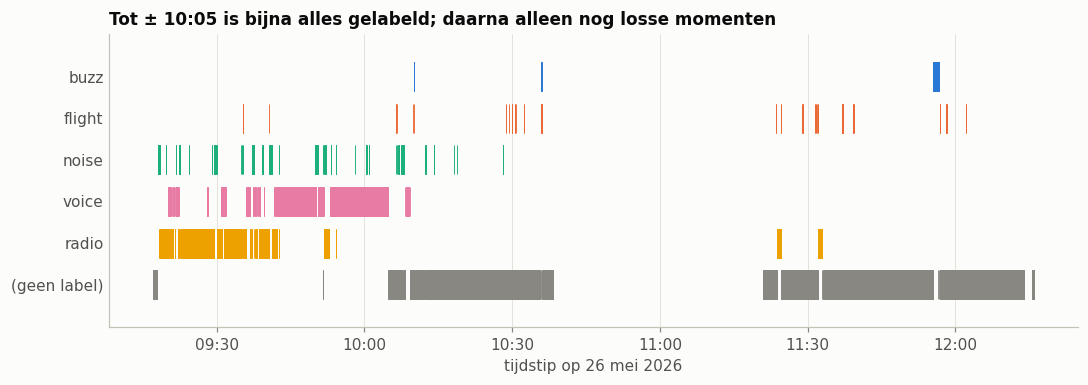

In [62]:
print("Gelabelde seconden per uur van de dag:")
print(lab["start_dt"].dt.hour.value_counts().sort_index().rename("seconden"))

dag = df[df["datum"] == pd.Timestamp("2026-05-26").date()]
rijen = ["(geen label)", "radio", "voice", "noise", "flight", "buzz"]
kleur_rij = {**KLEUR, "(geen label)": GRIJS}
dag_label = dag["label"].fillna("(geen label)")

fig, ax = plt.subplots(figsize=(10, 3.6))
for y, naam in enumerate(rijen):
    tijden = mdates.date2num(dag.loc[dag_label == naam, "start_dt"])
    ax.eventplot(tijden, lineoffsets=y, linelengths=0.7, linewidths=0.6, colors=kleur_rij[naam])
ax.set_yticks(range(len(rijen)), rijen)
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("tijdstip op 26 mei 2026")
ax.set_title("Tot ± 10:05 is bijna alles gelabeld; daarna alleen nog losse momenten")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

**Observatie:** de gelabelde data komt van 3 van de 5 opnamedagen en valt tussen 9 en 14 uur; 2.517 van de 3.716 gelabelde seconden liggen tussen 9 en 10 uur. Op 26 mei is tot ± 10:05 bijna elke seconde gelabeld, daarna alleen losse momenten (vooral `flight` en `buzz`).

**Gevolg:** het model ziet weinig variatie in dag en tijdstip. Het is onzeker hoe goed het werkt op andere momenten.

### 5.2 Label ↔ feature: eerst alle opnames, dan per recorder

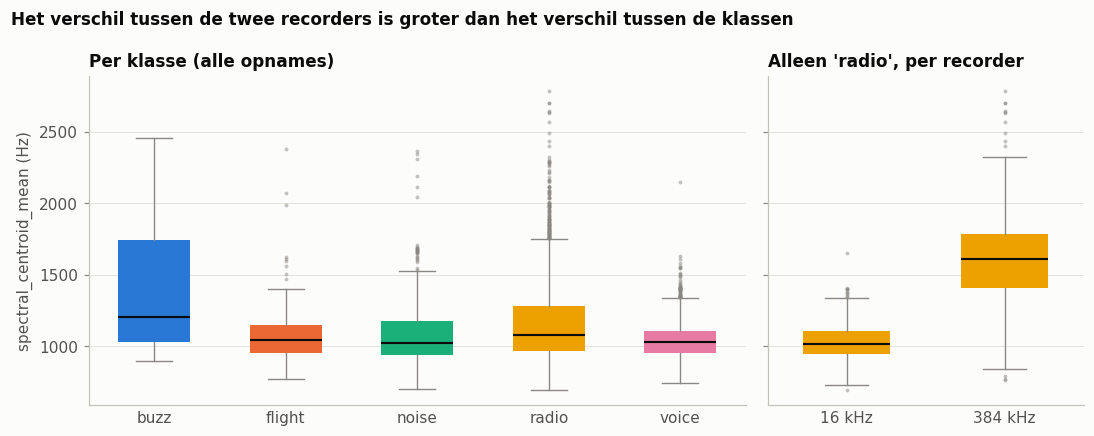

Gemiddelde per klasse, met en zonder de 384 kHz-opnames:
       alle opnames                                              alleen 16 kHz                                             
           zcr_mean spectral_centroid_mean spectral_rolloff_mean      zcr_mean spectral_centroid_mean spectral_rolloff_mean
label                                                                                                                      
buzz          0.077               1381.849              3088.965         0.063               1156.103              2400.911
flight        0.058               1094.440              2310.525         0.054               1038.462              2163.936
noise         0.068               1107.025              2309.240         0.066               1076.845              2223.889
radio         0.069               1185.106              2573.155         0.059               1026.048              2136.855
voice         0.065               1044.538              2107.052         0.

In [63]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True, gridspec_kw={"width_ratios": [5, 2.4]})

boxplot_per_klasse(ax1, lab, "spectral_centroid_mean")
ax1.set_title("Per klasse (alle opnames)")
ax1.set_ylabel("spectral_centroid_mean (Hz)")

radio = lab[lab["label"] == "radio"]
recorders = ["16 kHz", "384 kHz"]
bp = ax2.boxplot([radio.loc[radio["recorder"] == r, "spectral_centroid_mean"] for r in recorders],
                 tick_labels=recorders, **BOX_STIJL)
for vak in bp["boxes"]:
    vak.set(facecolor=KLEUR["radio"], edgecolor="none")
ax2.set_title("Alleen 'radio', per recorder")
ax2.grid(axis="x", visible=False)
ax2.tick_params(axis="x", length=0)

fig.suptitle("Het verschil tussen de twee recorders is groter dan het verschil tussen de klassen",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

SPECTRAAL = ["zcr_mean", "spectral_centroid_mean", "spectral_rolloff_mean"]
lab16 = lab[lab["recorder"] == "16 kHz"]
vergelijking = pd.concat(
    {"alle opnames": lab.groupby("label")[SPECTRAAL].mean(),
     "alleen 16 kHz": lab16.groupby("label")[SPECTRAAL].mean()},
    axis=1,
).round(3)
print("Gemiddelde per klasse, met en zonder de 384 kHz-opnames:")
print(vergelijking)
print("\nAlleen 'buzz', per recorder:")
print(lab[lab["label"] == "buzz"].groupby("recorder")[SPECTRAAL].mean().round(3))

**Observatie:** over alle opnames lijkt `buzz` veel "helderder" dan de andere klassen (gemiddelde centroid 1.382 Hz). Maar de `buzz`-seconden uit de 384 kHz-opnames hebben een gemiddelde centroid van 1.784 Hz, en die trekken het gemiddelde omhoog. **Binnen de 16 kHz-opnames** is het verschil veel kleiner: `buzz` 1.156 Hz tegenover 1.026 – 1.077 Hz voor de andere klassen.

**Conclusie:** `buzz` is wel iets helderder, maar het grootste deel van het verschil komt door de recorder. Bij elke vergelijking tussen klassen moeten we daarom ook naar de recorder kijken.

### 5.3 De belangrijkste features per klasse (alleen 16 kHz)

Zelfde soort boxplots als in de eerste EDA, maar nu alleen op de 16 kHz-opnames, zodat het recorder-effect er niet doorheen loopt. Uitschieters zijn weggelaten voor de leesbaarheid.

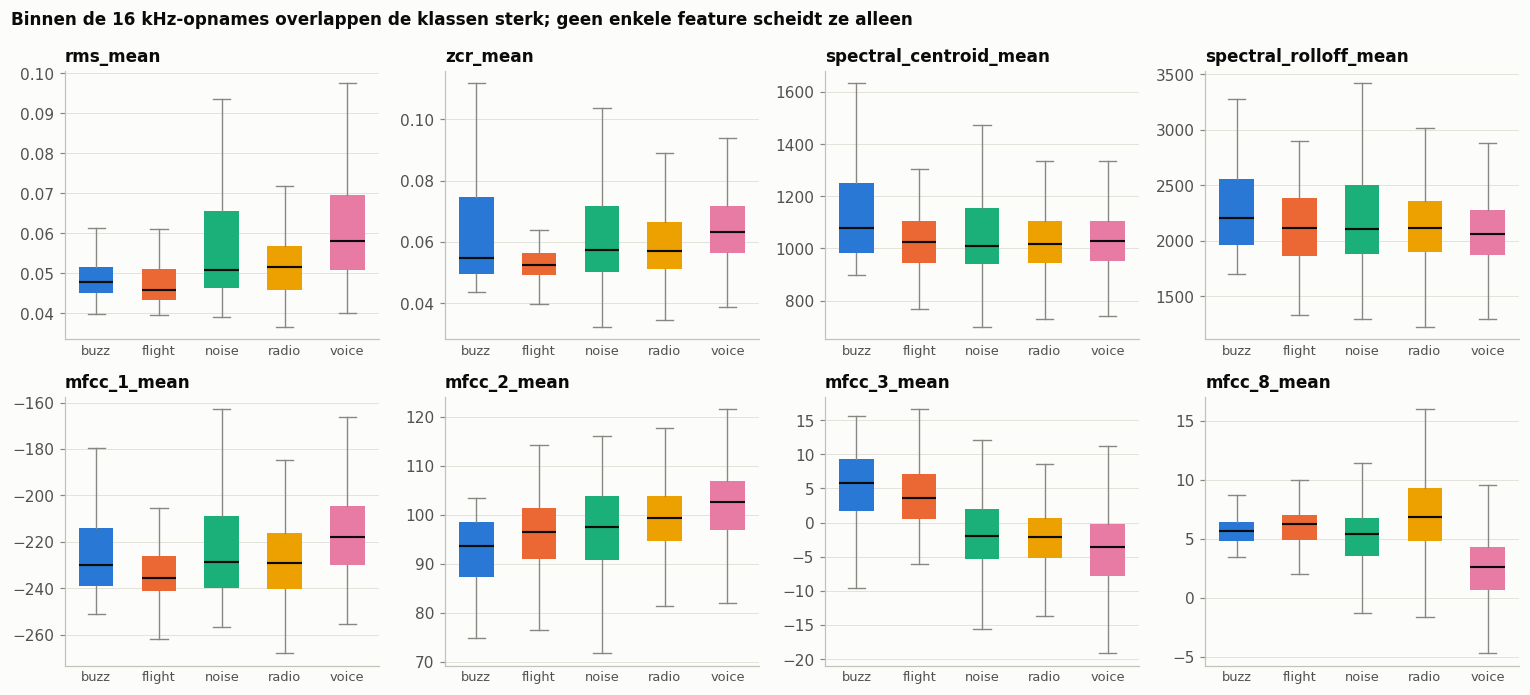

In [64]:
key_feats = ["rms_mean", "zcr_mean", "spectral_centroid_mean", "spectral_rolloff_mean",
             "mfcc_1_mean", "mfcc_2_mean", "mfcc_3_mean", "mfcc_8_mean"]

fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
for ax, kolom in zip(axes.ravel(), key_feats):
    boxplot_per_klasse(ax, lab16, kolom, toon_uitschieters=False)
    ax.set_title(kolom)
    ax.tick_params(axis="x", labelsize=8.5)
fig.suptitle("Binnen de 16 kHz-opnames overlappen de klassen sterk; geen enkele feature scheidt ze alleen",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Observatie:** de verdelingen overlappen grotendeels. `voice` en `noise` zijn het luidst, `buzz` ligt iets hoger op de spectrale features en op `mfcc_3`, en `mfcc_8` verschilt het meest tussen de klassen (zie ook 5.6). Een model heeft dus **combinaties van features** nodig.

### 5.4 MFCC-profiel per klasse (alleen 16 kHz)

Per klasse het gemiddelde van MFCC 2 t/m 20, **min het gemiddelde over alle klassen**. Zo zie je per coëfficiënt welke klasse afwijkt; zonder die correctie verdwijnen de verschillen omdat `mfcc_2` (± 100) de schaal bepaalt. MFCC 1 laten we weg: die zegt vooral iets over de totale energie. De hogere coëfficiënten beschrijven de vorm van het spectrum.

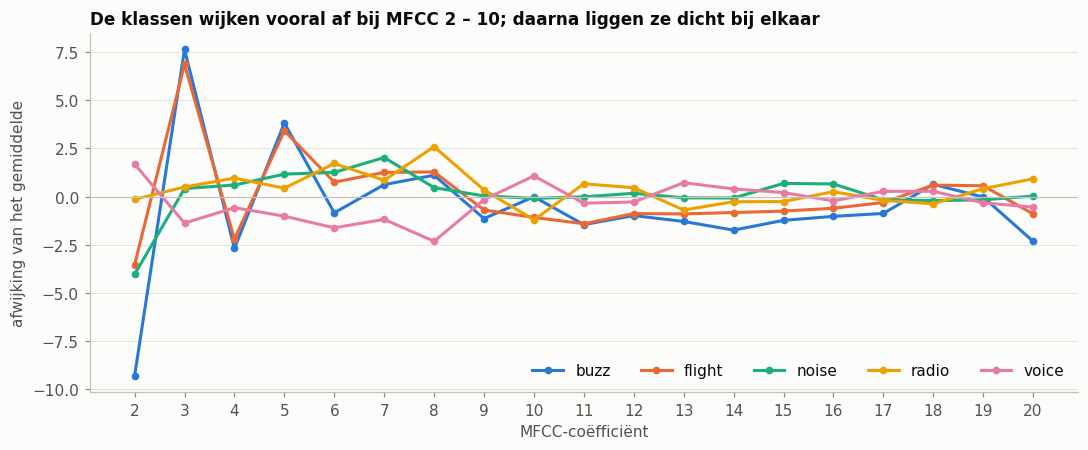

In [71]:
mfcc_kolommen = [f"mfcc_{i}_mean" for i in range(2, 21)]
profiel = lab16.groupby("label")[mfcc_kolommen].mean() - lab16[mfcc_kolommen].mean()
nummers = range(2, 21)

fig, ax = plt.subplots(figsize=(10, 4.2))
for klasse in KLASSEN:
    ax.plot(nummers, profiel.loc[klasse], color=KLEUR[klasse], linewidth=2, marker="o", markersize=4, label=klasse)
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xticks(list(nummers))
ax.set_xlabel("MFCC-coëfficiënt")
ax.set_ylabel("afwijking van het gemiddelde")
ax.set_title("De klassen wijken vooral af bij MFCC 2 – 10; daarna liggen ze dicht bij elkaar")
ax.legend(ncols=5, loc="lower right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Observatie:** waar de lijnen uit elkaar lopen, verschilt de klankkleur tussen de klassen. Dat gebeurt vooral bij MFCC 2 – 10; daarna liggen de lijnen dicht bij nul. Opvallend: `buzz` en `flight` wijken bij MFCC 2 – 5 op bijna dezelfde manier af. Ze verschillen dus vooral van de andere klassen, maar lijken onderling op elkaar – het model zal juist moeite hebben om die twee uit elkaar te houden. `voice` wijkt het meest af bij MFCC 3 – 8.

### 5.5 Feature ↔ feature: correlaties

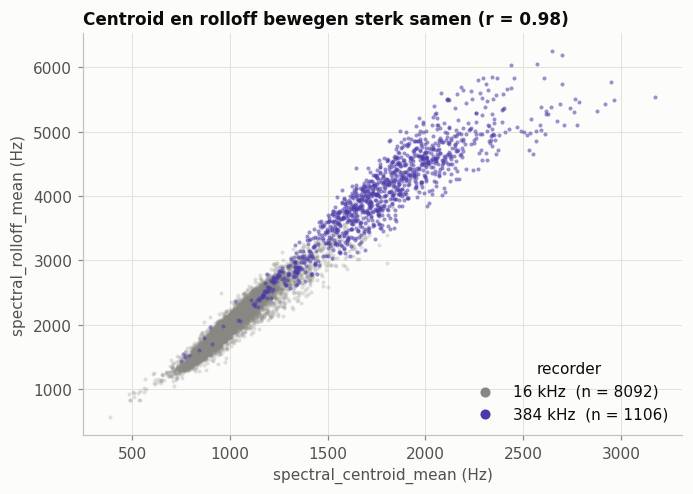

In [66]:
r = df["spectral_centroid_mean"].corr(df["spectral_rolloff_mean"])

fig, ax = plt.subplots(figsize=(6.4, 4.6))
for naam, kleur, alpha in [("16 kHz", GRIJS, 0.25), ("384 kHz", ACCENT, 0.55)]:
    deel = df[df["recorder"] == naam]
    ax.scatter(deel["spectral_centroid_mean"], deel["spectral_rolloff_mean"],
               s=7, color=kleur, alpha=alpha, linewidths=0, label=f"{naam}  (n = {len(deel)})")
ax.set_xlabel("spectral_centroid_mean (Hz)")
ax.set_ylabel("spectral_rolloff_mean (Hz)")
ax.set_title(f"Centroid en rolloff bewegen sterk samen (r = {r:.2f})")
legenda = ax.legend(title="recorder", loc="lower right", markerscale=2.5)
for handle in legenda.legend_handles:
    handle.set_alpha(1)
plt.tight_layout()
plt.show()

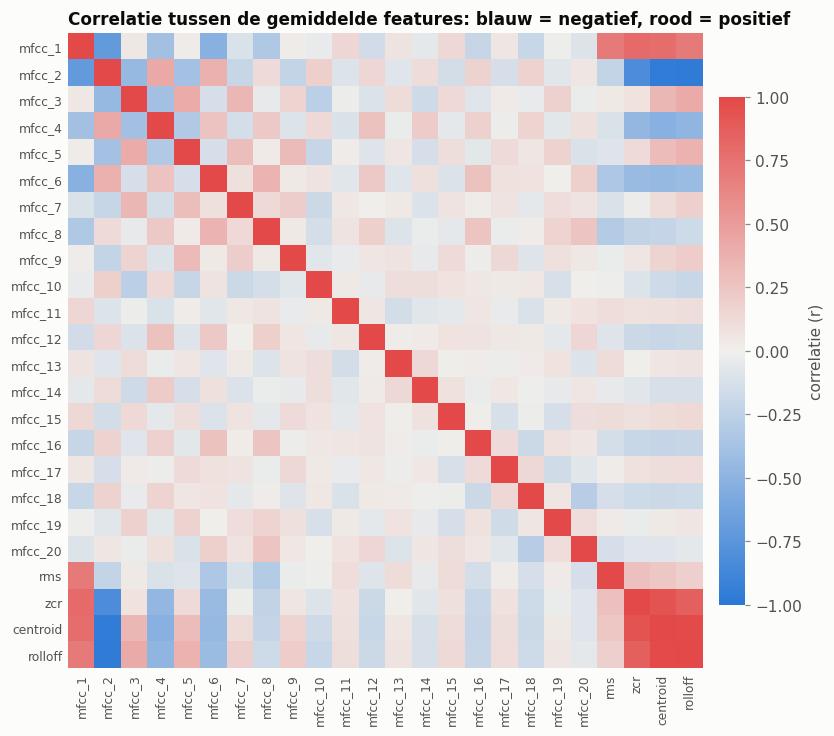

Paren met |r| > 0,85 (over alle 64 features): 5
                                                  r
spectral_centroid_mean spectral_rolloff_mean   0.98
mfcc_2_mean            spectral_rolloff_mean  -0.97
                       spectral_centroid_mean -0.96
zcr_mean               spectral_centroid_mean  0.93
                       spectral_rolloff_mean   0.86


In [67]:
mean_features = [f"mfcc_{i}_mean" for i in range(1, 21)] + BASIS
corr = df[mean_features].corr()

blauw_grijs_rood = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(8.2, 6.8))
im = ax.imshow(corr, cmap=blauw_grijs_rood, vmin=-1, vmax=1)
korte_namen = [n.replace("_mean", "").replace("spectral_", "") for n in mean_features]
ax.set_xticks(range(len(korte_namen)), korte_namen, rotation=90, fontsize=8)
ax.set_yticks(range(len(korte_namen)), korte_namen, fontsize=8)
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
balk = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
balk.set_label("correlatie (r)")
balk.outline.set_visible(False)
ax.set_title("Correlatie tussen de gemiddelde features: blauw = negatief, rood = positief")
plt.tight_layout()
plt.show()

alle_corr = df[FEATURES].corr()
boven = alle_corr.where(np.triu(np.ones(alle_corr.shape, dtype=bool), k=1)).stack()
sterk = boven[boven.abs() > 0.85].sort_values(key=abs, ascending=False)
print(f"Paren met |r| > 0,85 (over alle 64 features): {len(sterk)}")
print(sterk.round(2).to_frame("r"))

**Observatie:** er zijn 5 sterk gecorreleerde paren, allemaal rond de spectrale "helderheid": `spectral_centroid`, `spectral_rolloff` en `zcr` bewegen samen, en `mfcc_2` beweegt er tegenin. Deze vier features meten grotendeels hetzelfde. Voor lineaire modellen kan het helpen er één of twee van te houden; boommodellen (Random Forest, XGBoost) hebben hier weinig last van.

### 5.6 Welke features onderscheiden de klassen? (ANOVA F-score)

Per feature een ANOVA F-test: hoe hoger de F-score, hoe meer de gemiddelden van de groepen verschillen ten opzichte van de spreiding binnen de groepen. We doen de test drie keer:

- klassen, alle opnames (zoals in de eerste EDA)
- klassen, alleen 16 kHz-opnames
- de twee **recorders** als groepen – om te zien welke features vooral het recorder-verschil meten

In [68]:
F_alle, _ = f_classif(lab[FEATURES], lab["label"])
F_16, _ = f_classif(lab16[FEATURES], lab16["label"])
F_rec, _ = f_classif(lab[FEATURES], lab["recorder"])
fscores = pd.DataFrame(
    {"klasse, alle opnames": F_alle, "klasse, alleen 16 kHz": F_16, "recorder": F_rec},
    index=FEATURES,
)
rang = fscores.rank(ascending=False).astype(int)

print("Top 8 volgens de eerste EDA (klasse, alle opnames) – met hun rang in de andere twee tests:")
top8 = fscores["klasse, alle opnames"].nlargest(8).index
print(fscores.loc[top8].round(0).astype(int).join(rang.loc[top8], rsuffix=" (rang)"))

Top 8 volgens de eerste EDA (klasse, alle opnames) – met hun rang in de andere twee tests:
              klasse, alle opnames  klasse, alleen 16 kHz  recorder  klasse, alle opnames (rang)  klasse, alleen 16 kHz (rang)  \
mfcc_10_mean                   299                    193       807                            1                             2   
mfcc_7_mean                    236                    140      1446                            2                             7   
mfcc_3_mean                    212                    103      3774                            3                            13   
mfcc_5_mean                    198                     84      4460                            4                            21   
mfcc_8_mean                    176                    433       385                            5                             1   
mfcc_2_mean                    163                     68      5208                            6                            23   

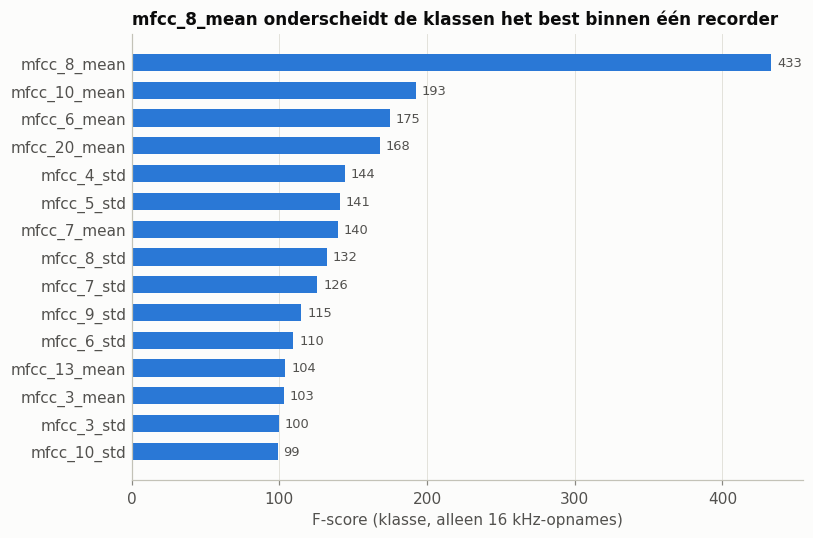

In [69]:
top = fscores["klasse, alleen 16 kHz"].nlargest(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(top.index, top.values, color=KLEUR["buzz"], height=0.62)
for y, v in enumerate(top.values):
    ax.text(v + 4, y, f"{v:.0f}", va="center", color=INKT_2, fontsize=8.5)
ax.set_xlabel("F-score (klasse, alleen 16 kHz-opnames)")
ax.set_title("mfcc_8_mean onderscheidt de klassen het best binnen één recorder")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

**Observatie:** over alle opnames staan `mfcc_10`, `mfcc_7`, `mfcc_3`, `mfcc_5` en `mfcc_2` bovenaan. Maar `mfcc_2`, `mfcc_3` en `mfcc_5` zijn ook de features die **de twee recorders** het sterkst van elkaar scheiden. Binnen de 16 kHz-opnames verandert de top: `mfcc_8_mean` staat dan duidelijk bovenaan, gevolgd door `mfcc_10` en `mfcc_6`.

**Conclusie:** de MFCC-gemiddelden zijn het meest onderscheidend, en de eenvoudige features (`rms`, `zcr`) staan lager. Maar de ranglijst over alle opnames is deels een ranglijst van recorder-verschillen.

> Let op: de F-test kijkt naar één feature tegelijk en alleen naar verschillen in gemiddelden.

### 5.7 PCA – alle features in twee dimensies

De gestandaardiseerde features (alleen gelabelde seconden) teruggebracht naar 2 dimensies. Om overlap te vermijden staat elke klasse in een eigen paneel, tegen de rest in het grijs. Het laatste paneel toont de 384 kHz-opnames.

PC1: 14.3%  |  PC2: 10.4%  |  samen: 24.7%
10 componenten samen: 45.4%


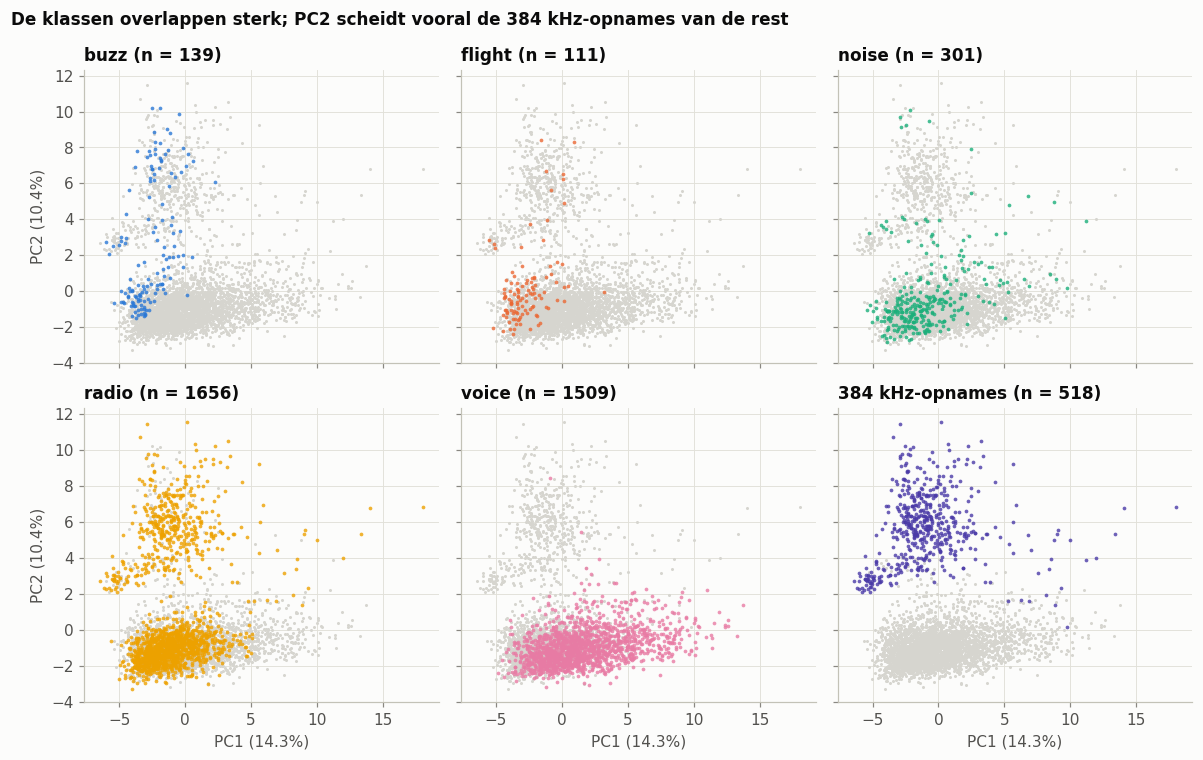


Mediaan van PC1 en PC2 per recorder:
           PC1   PC2
recorder            
16 kHz   -0.45 -1.04
384 kHz  -1.22  5.62


In [70]:
X = StandardScaler().fit_transform(lab[FEATURES])
pca = PCA(n_components=10).fit(X)
Z = pca.transform(X)
verklaard = pca.explained_variance_ratio_
print(f"PC1: {verklaard[0]:.1%}  |  PC2: {verklaard[1]:.1%}  |  samen: {verklaard[:2].sum():.1%}")
print(f"10 componenten samen: {verklaard.sum():.1%}")

panelen = [(k, KLEUR[k], (lab["label"] == k).to_numpy()) for k in KLASSEN]
panelen.append(("384 kHz-opnames", ACCENT, (lab["recorder"] == "384 kHz").to_numpy()))

fig, axes = plt.subplots(2, 3, figsize=(11, 7), sharex=True, sharey=True)
for ax, (naam, kleur, masker) in zip(axes.ravel(), panelen):
    ax.scatter(Z[~masker, 0], Z[~masker, 1], s=4, color=LICHTGRIJS, linewidths=0)
    ax.scatter(Z[masker, 0], Z[masker, 1], s=6, color=kleur, alpha=0.8, linewidths=0)
    ax.set_title(f"{naam} (n = {masker.sum()})")
for ax in axes[1]:
    ax.set_xlabel(f"PC1 ({verklaard[0]:.1%})")
for ax in axes[:, 0]:
    ax.set_ylabel(f"PC2 ({verklaard[1]:.1%})")
fig.suptitle("De klassen overlappen sterk; PC2 scheidt vooral de 384 kHz-opnames van de rest",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nMediaan van PC1 en PC2 per recorder:")
print(pd.DataFrame(Z[:, :2], columns=["PC1", "PC2"], index=lab.index).groupby(lab["recorder"]).median().round(2))

**Observatie:** PC1 verklaart 14,3% en PC2 10,4% van de variantie; met 10 componenten is pas ± 45% verklaard. De informatie zit dus verspreid over veel dimensies. In twee dimensies overlappen de klassen sterk. **De tweede as (PC2) scheidt vooral de 384 kHz-opnames van de rest** – de grootste structuur na PC1 is dus het verschil tussen de recorders, niet tussen de klassen.

**Conclusie:** er is geen eenvoudige lineaire scheiding in twee dimensies. Dat betekent niet dat classificatie onmogelijk is: niet-lineaire modellen kunnen nog steeds goed presteren.

## 6. Vervolgvragen – onze EDA-output

### 3 observaties

1. **De klassen zijn sterk uit balans.** Van de 3.716 gelabelde seconden is 45% `radio` en 41% `voice`. `buzz` (139 seconden, 13 bestanden) en `flight` (111 seconden) zijn samen maar 7%.
2. **De recorder bepaalt de features sterker dan de klasse.** De 12 opnames op 384 kHz liggen in boxplots, ANOVA en PCA duidelijk apart van de 138 opnames op 16 kHz, ook binnen dezelfde klasse. Het "heldere" geluid van `buzz` komt voor een groot deel daardoor.
3. **Labels zijn geclusterd in tijd en in bestanden.** Labels komen in aaneengesloten blokken, vooral tussen 9 en 10 uur op één dag, en meer dan de helft van de `buzz`-seconden komt uit 2 bestanden.

### 2 kwaliteitsissues

1. **Elke rij staat dubbel in het CSV-bestand** (9.198 van 18.396 rijen). Oorzaak: `preprocessdata.py` leest elk WAV-bestand twee keer in.
2. **60% van de seconden heeft geen label**, en het is niet duidelijk wat "geen label" betekent. Daarnaast hebben 81 labels geen bijbehorende audio.

### 1 vervolgvraag (voor de opdrachtgever)

> **Wat betekent een seconde zonder label?** Is daar niets relevants te horen, of is die seconde nog niet beluisterd?

De overige vragen aan de opdrachtgever staan in het document *Datakwaliteit hommelopnames* (PDF).

### Aanbevelingen voor de volgende stap

| Bevinding | Aanbeveling |
|---|---|
| Elke rij staat er twee keer in | `preprocessdata.py` aanpassen en het feature-bestand opnieuw genereren |
| ≈ 60% van de seconden heeft geen label | Eerst navragen wat het betekent. Tot dan niet gebruiken voor supervised training; later eventueel voor semi-supervised learning of anomaliedetectie |
| Twee soorten recorders | Resultaten apart rapporteren per recorder; na het antwoord van de opdrachtgever beslissen of we alleen 16 kHz gebruiken of beide |
| Labels geclusterd per opname | Train/test splitsen **per `source_file`** (`GroupKFold`) |
| Sterke klasse-onbalans | Class weights of resampling (bijv. SMOTE, alleen binnen de trainset) en evalueren met **macro-F1** en recall per klasse in plaats van accuracy |
| Grote verschillen in schaal | Features standaardiseren (`StandardScaler`, of `RobustScaler` vanwege de uitschieters), alleen fitten op de trainset |
| Spectrale features sterk gecorreleerd | Bij lineaire modellen er één of twee van houden |
| MFCC-gemiddelden het meest onderscheidend | Goede basis voor het model; binnen 16 kHz vooral `mfcc_8`, `mfcc_10` en `mfcc_6` |
| Weinig lineaire scheiding (PCA) | Niet-lineaire modellen proberen (Random Forest, gradient boosting, neuraal netwerk) |
| Labels alleen van 3 dagen, 9 – 14 uur | Bij de opdrachtgever navragen of er meer opnames van andere dagen en tijden zijn |